# Python ile Karar Ağacı Oluşturma
1. Ekrana yazı yazdırma
2. Hazır araçları kullanma - kütüphane
3. veriyi tanıma
4. Veriyi test eğitim olarak ayırma
5. Karar ağacı oluşturma
6. Derinliği siz seçin
7. Optimum derinliği bulma
8. Final ağaç ve confusion matrix
9. Yeni bir veri setinde çalışma


In [ ]:
# print() ile ekrana yazı yazma
print("Hello World!")
print(589)

Hello World!
589


In [ ]:
print("Merhaba, ben Amy.")

Merhaba, ben Amy.


In [ ]:
# Değişken oluşturma: = işareti ile oluşturulur
yas = 21
isim = "Amy"

print(yas)
print(isim)

21
Amy


In [ ]:
benim_yasim = 23
favori_yiyecek = "yaprak sarma"

print("Ben", benim_yasim, "yaşındayım ve en sevidğim yiyecek", favori_yiyecek, ".")

Ben 23 yaşındayım ve en sevidğim yiyecek yaprak sarma .


In [ ]:
# Bir liste oluşturma: [] ile yazılır
yiyecekler = ["elma", "fındıklı gofret", "patalmış mısır", "bezelye", "jelibon"]
print(yiyecekler)

['elma', 'fındıklı gofret', 'patalmış mısır', 'bezelye', 'jelibon']


In [ ]:
ogrenci = ["Marco", 22, "Ulysses", 19, "Sheila", 20]
print(ogrenci)

['Marco', 22, 'Ulysses', 19, 'Sheila', 20]


In [ ]:
len(yiyecekler)
print("Yyiecekler listesinde", len(yiyecekler), "tane yiyecek vardır.")

Yyiecekler listesinde 5 tane yiyecek vardır.


# Kütüphaneleri Tanıma

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
print("Kütüphaneler başarı ile yüklendi.")


Kütüphaneler başarı ile yüklendi.


In [ ]:
pip install pandas

In [ ]:
# Veriyi okuma: df data frame'in kısaltması ve "tablo" demektir
df = pd.read_csv("/content/Food_Dataset_Turkish (2).csv")

# Veri setini ilk 5 satırına bakma
df.head(10)

,Ürün Adı,Enerji (kcal),Yağ (g),Doymuş Yağ (g),Karbonhidrat (g),Şeker (g),Protein (g),Tuz (g),Öneri
0,Fındıklı Gofret,542,31.9,18.6,54.0,42.6,7.6,0.4,Tavsiye edilemez
1,Patlamış Mısır,499,23.0,13.8,57.0,3.8,10.7,1.8,Tavsiye edilemez
2,Elma,52,0.2,0.0,13.8,11.0,0.3,0.0,Tavsiye edilebilir
3,Çavdar Ekmeği,229,4.9,0.8,35.0,2.3,7.7,1.0,Tavsiye edilebilir
4,Muz,95,0.3,0.1,21.0,12.0,1.1,0.1,Tavsiye edilebilir
5,Patates Cipsi,503,28.0,2.6,53.0,2.9,6.3,2.8,Tavsiye edilemez
6,Çubuk Kraker,392,5.9,0.8,71.0,3.4,12.0,4.5,Tavsiye edilemez
7,Makarna,359,2.0,0.5,70.9,3.5,12.8,0.0,Tavsiye edilebilir
8,Patates Kızartması,289,14.0,1.3,36.0,0.3,3.4,0.7,Tavsiye edilemez
9,Bezelye,86,1.0,0.2,9.4,3.5,6.4,0.0,Tavsiye edilebilir


In [ ]:
df.tail(15)

,Ürün Adı,Enerji (kcal),Yağ (g),Doymuş Yağ (g),Karbonhidrat (g),Şeker (g),Protein (g),Tuz (g),Öneri
40,Pirinç,349,0.9,0.3,77.3,0.3,7.3,0.0,Tavsiye edilebilir
41,Balık Kroket,195,7.7,0.6,18.0,0.8,13.0,1.0,Tavsiye edilebilir
42,Havuç,31,0.2,0.1,4.7,4.6,0.9,0.0,Tavsiye edilebilir
43,Somun Ekmek,271,1.6,0.5,55.0,1.2,8.0,1.7,Tavsiye edilemez
44,Dolmalık Biber,43,0.5,0.0,6.4,6.4,1.3,0.2,Tavsiye edilebilir
45,Vegan Salam,345,33.0,23.0,5.8,1.6,5.7,1.6,Tavsiye edilemez
46,Fiyonk Kraker,295,5.4,0.3,51.0,2.7,8.9,2.1,Tavsiye edilemez
47,Kaşar Peyniri,345,33.0,23.0,5.8,1.6,5.7,1.6,Tavsiye edilebilir
48,Ketçap,101,0.5,0.1,20.0,19.0,1.7,1.8,Tavsiye edilemez
49,Margarin,720,80.0,23.0,0.0,0.0,0.0,0.2,Tavsiye edilemez


In [ ]:
# Veride kaç tane satır / sütun var?
satir_sayisi = df.shape[0]
sutun_sayisi = df.shape[1]

print("Bu tabloda", satir_sayisi, "tane satır ve", sutun_sayisi, "tane sütun vardır.")

Bu tabloda 55 tane satır ve 9 tane sütun vardır.


In [ ]:
# HEr sınıftan kaç tane var?
df["Öneri"].value_counts()

,count
Öneri,
Tavsiye edilemez,29
Tavsiye edilebilir,26


In [ ]:
# Sayısal özet oluşturma
df.describe().round(1)

,Enerji (kcal),Yağ (g),Doymuş Yağ (g),Karbonhidrat (g),Şeker (g),Protein (g),Tuz (g)
count,55.0,55.0,55.0,55.0,55.0,55.0,55.0
mean,288.2,15.4,5.9,29.0,11.5,7.2,0.9
std,201.1,20.9,9.8,28.3,18.0,6.2,1.2
min,7.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,106.0,0.5,0.1,3.2,0.8,1.6,0.0
50%,279.0,7.3,1.5,18.0,2.3,6.4,0.3
75%,405.5,22.5,6.8,54.5,13.5,11.2,1.6
max,743.0,82.0,55.0,86.9,71.6,24.0,5.5


In [ ]:
# Şekere göre azalan sıralama
df.sort_values("Şeker (g)", ascending=False).head()

,Ürün Adı,Enerji (kcal),Yağ (g),Doymuş Yağ (g),Karbonhidrat (g),Şeker (g),Protein (g),Tuz (g),Öneri
53,Karamelli Şeker,424,8.4,5.7,86.9,71.6,0.3,1.0,Tavsiye edilemez
31,Hurma,279,0.2,0.1,73.0,60.0,2.2,0.0,Tavsiye edilebilir
26,Sütlü Çikolata,530,29.5,17.5,58.5,57.5,6.6,0.2,Tavsiye edilemez
38,Ahududu Reçeli,223,0.2,0.0,52.2,51.7,0.7,0.0,Tavsiye edilemez
35,Jelibon,343,0.1,0.1,77.0,46.0,6.9,0.1,Tavsiye edilemez


In [ ]:
# Yağa göre artan sıralama
df.sort_values("Yağ (g)", ascending=True).head()

,Ürün Adı,Enerji (kcal),Yağ (g),Doymuş Yağ (g),Karbonhidrat (g),Şeker (g),Protein (g),Tuz (g),Öneri
10,Göbek Marul,7,0.0,0.0,0.7,0.7,0.5,0.0,Tavsiye edilebilir
20,Salatalık,12,0.1,0.0,3.6,1.7,0.7,0.0,Tavsiye edilebilir
25,Patates,71,0.1,0.0,15.0,0.8,1.7,2.0,Tavsiye edilebilir
35,Jelibon,343,0.1,0.1,77.0,46.0,6.9,0.1,Tavsiye edilemez
51,Domates,19,0.1,0.0,3.5,3.2,0.7,0.0,Tavsiye edilebilir


In [ ]:
df1 = df.sort_values(["Şeker (g)"], ascending=[False])
df2 = df1.sort_values(["Protein (g)"], ascending=[True])
print(df2.head)

<bound method NDFrame.head of               Ürün Adı  Enerji (kcal)  Yağ (g)  Doymuş Yağ (g)  \
49            Margarin            720     80.0            23.0   
53     Karamelli Şeker            424      8.4             5.7   
2                 Elma             52      0.2             0.0   
10         Göbek Marul              7      0.0             0.0   
24            Tereyağı            743     82.0            55.0   
20           Salatalık             12      0.1             0.0   
51             Domates             19      0.1             0.0   
38      Ahududu Reçeli            223      0.2             0.0   
42               Havuç             31      0.2             0.1   
4                  Muz             95      0.3             0.1   
27             Mayonez            721     79.3            10.0   
44      Dolmalık Biber             43      0.5             0.0   
32             Avokado            160     13.0             2.8   
54               Kabak             19      0.4

In [ ]:
df.sort_values(["Şeker (g)", "Protein (g)"], ascending=[False, True])

,Ürün Adı,Enerji (kcal),Yağ (g),Doymuş Yağ (g),Karbonhidrat (g),Şeker (g),Protein (g),Tuz (g),Öneri
53,Karamelli Şeker,424,8.4,5.7,86.9,71.6,0.3,1.0,Tavsiye edilemez
31,Hurma,279,0.2,0.1,73.0,60.0,2.2,0.0,Tavsiye edilebilir
26,Sütlü Çikolata,530,29.5,17.5,58.5,57.5,6.6,0.2,Tavsiye edilemez
38,Ahududu Reçeli,223,0.2,0.0,52.2,51.7,0.7,0.0,Tavsiye edilemez
35,Jelibon,343,0.1,0.1,77.0,46.0,6.9,0.1,Tavsiye edilemez
0,Fındıklı Gofret,542,31.9,18.6,54.0,42.6,7.6,0.4,Tavsiye edilemez
23,Waffle,459,24.3,12.7,53.0,33.8,7.5,0.3,Tavsiye edilemez
14,Mozaik Kek,447,26.0,14.0,54.0,33.0,5.4,0.4,Tavsiye edilemez
52,Sandviç Bisküvi,470,18.5,8.6,68.7,32.4,5.4,0.4,Tavsiye edilemez
50,Bitter Çikolata,582,43.0,26.0,37.0,29.0,6.7,0.0,Tavsiye edilemez


In [ ]:
# Özellikler (X) Ürün Adı ve Öneri dışındaki tüm sütunlar
X = df.drop(columns=["Ürün Adı", "Öneri"])

# Hedef değişken (y) sadece Öneri sütunu
y = df["Öneri"]

print(X.head())
print("\n")
print(y.head().tolist())

   Enerji (kcal)  Yağ (g)  Doymuş Yağ (g)  Karbonhidrat (g)  Şeker (g)  \
0            542     31.9            18.6              54.0       42.6   
1            499     23.0            13.8              57.0        3.8   
2             52      0.2             0.0              13.8       11.0   
3            229      4.9             0.8              35.0        2.3   
4             95      0.3             0.1              21.0       12.0   

   Protein (g)  Tuz (g)  
0          7.6      0.4  
1         10.7      1.8  
2          0.3      0.0  
3          7.7      1.0  
4          1.1      0.1  


['Tavsiye edilemez', 'Tavsiye edilemez', 'Tavsiye edilebilir', 'Tavsiye edilebilir', 'Tavsiye edilebilir']


In [ ]:
# %80 ve %20 oalrak veri setini ayırma
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size = 0.2,       # %20'si test veri seti olsun
    random_state = 42,    # aynı sonucu almak için
    stratify = y,         # İki sınıftan da orantıl al
)

print("Eğitim veri seti büyüklüğü:", len(X_egitim), "yiyecek")
print("Eğitim veri seti büyüklüğü:", len(y_egitim), "yiyecek")
print("\n")
print("Test veri seti büyüklüğü:", len(X_test), "yiyecek")
print("Test veri seti büyüklüğü:", len(y_test), "yiyecek")

Eğitim veri seti büyüklüğü: 44 yiyecek
Eğitim veri seti büyüklüğü: 44 yiyecek


Test veri seti büyüklüğü: 11 yiyecek
Test veri seti büyüklüğü: 11 yiyecek


Karar Ağacı Oluşturma

In [ ]:
# Tek seviyeli karar ağacı oluşturma
agac1 = DecisionTreeClassifier(max_depth=1, random_state=42)

# Ağacı eğitim verisi ile eğitme (fit = eğitmek)
agac1.fit(X_egitim, y_egitim)

print("Tek seviyeli karar ağacımız eğitildi.")


Tek seviyeli karar ağacımız eğitildi.


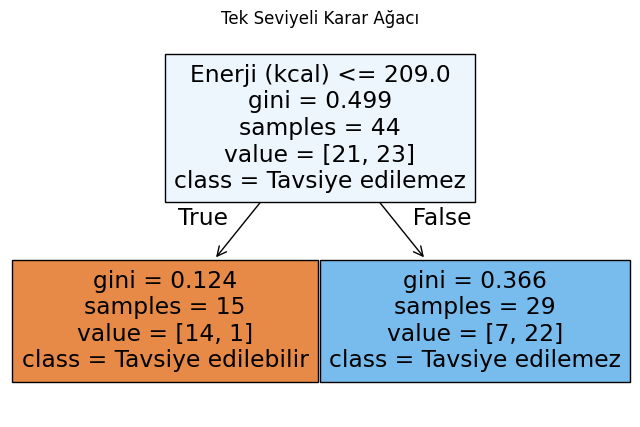

In [ ]:
# Karar ağacını görselleştirme
plt.figure(figsize=(8,5))          # Tuval boyutunu ayarlama
plot_tree(agac1,                         # Çizimi başlatma
     feature_names = X.columns,      # Değişken isimlerini belrileme
     class_names = agac1.classes_,   # Hedfef değişkenin isimlerini belirleme
     filled = True,)                 # Renki hale getirme
plt.title("Tek Seviyeli Karar Ağacı")
plt.show()

## Tek Seviyeli Karar Ağacı Ne KAdar Başarılı?

In [ ]:
# Duyarlılık (sensitivity) değerlerini hesaplama
tahminler_egitim = agac1.predict(X_egitim)
tahminler_test = agac1.predict(X_test)

from sklearn.metrics import recall_score

# Benim için pozitif olan yanş odaklandığım sınıf "Tavsiye edilebilir"dir
# Hesaplamayı buna göre yapacağız

# Eğitim verisinde duyarlılığı hesaplama
duyarlilik_egitim1 = recall_score(y_egitim, tahminler_egitim, pos_label="Tavsiye edilebilir")

# Test verisinde duyarlılığı hesaplama
duyarlilik_test1 = recall_score(y_test, tahminler_test, pos_label="Tavsiye edilebilir")

print(f"Eğitim duyarlılık: {duyarlilik_egitim1:.2%}")
print(f"Test duyarlılık: {duyarlilik_test1:.2%}")

Eğitim duyarlılık: 66.67%
Test duyarlılık: 80.00%


Misclassification Rate - MCR / Yanlış Sınıflandırma Oranı
## MCR = 1 - Accuracy

In [ ]:
from sklearn.metrics import accuracy_score

tahminler_egitim = agac1.predict(X_egitim)
tahminler_test = agac1.predict(X_test)

# Eğitim veriisnde MCR hesaplama
mcr_egitim1 = 1 - accuracy_score(y_egitim, tahminler_egitim)

# Test verisinde MCR hesaplama
mcr_test1 = 1 - accuracy_score(y_test, tahminler_test)

print(f"Eğitim yanlış sınıflandırma oranı: {mcr_egitim1:.2%}")
print(f"Test yanlış sınıflandırma oranı: {mcr_test1:.2%}")

Eğitim yanlış sınıflandırma oranı: 18.18%
Test yanlış sınıflandırma oranı: 27.27%


In [ ]:
#derinliğini benim seçtiğim DT'yi oluşturma
benim_seçimim=5

# Tek seviyeli karar ağacı oluşturma
agac2 = DecisionTreeClassifier(max_depth=benim_seçimim, random_state=42)

# Ağacı eğitim verisi ile eğitme (fit = eğitmek)
agac2.fit(X_egitim, y_egitim)

print("Çok seviyeli karar ağacımız eğitildi.")


Çok seviyeli karar ağacımız eğitildi.


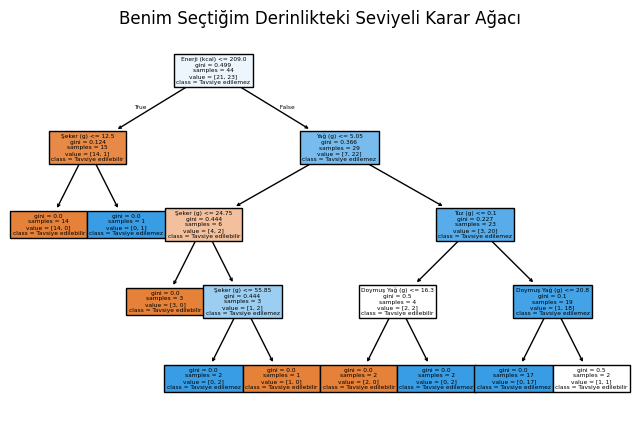

In [ ]:

plt.figure(figsize=(8,5))          # Tuval boyutunu ayarlama
plot_tree(agac2,                         # Çizimi başlatma
     feature_names = X.columns,      # Değişken isimlerini belrileme
     class_names = agac2.classes_,   # Hedfef değişkenin isimlerini belirleme
     filled = True,)                 # Renki hale getirme
plt.title("Benim Seçtiğim Derinlikteki Seviyeli Karar Ağacı")
plt.show()

In [ ]:
ogrenciler = ("Marco" , "Nadia" ,"Amy" ,"Bruno" , "Classmate")
for ogrenci in ogrenciler:
  print("Merhaba " + ogrenci +"!")

Merhaba Marco!
Merhaba Nadia!
Merhaba Amy!
Merhaba Bruno!
Merhaba Classmate!


In [ ]:
sonuclar_egitim=[]
sonuclar_test=[]
derinlikler=[1,2,3,4,5,6,7,8,9,10] #Derneyeceğimiz derinliklerin tamamı

In [ ]:
#Ağacı o anki derinliğe göre oluşturma
for derinlik in derinlikler:
  # karar ağacı oluşturma
  agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)

  # Ağacı eğitim verisi ile eğitme (fit = eğitmek)
  agac.fit(X_egitim, y_egitim)

  # MCR değerlerini hesaplama
  mcr_egitim = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
  mcr_test = 1 - accuracy_score(y_test, agac.predict(X_test))

  #Sonuçları boş kutulara ( listelere ) ekle
  sonuclar_egitim.append(mcr_egitim)
  sonuclar_test.append(mcr_test)

  #Ekrana "yazdırma"
  print(f"Derinlik: {derinlik} MCR Eğitim: {mcr_egitim:.2%} Test: {mcr_test:.2%}")




Derinlik: 1 MCR Eğitim: 18.18% Test: 27.27%
Derinlik: 2 MCR Eğitim: 11.36% Test: 9.09%
Derinlik: 3 MCR Eğitim: 9.09% Test: 9.09%
Derinlik: 4 MCR Eğitim: 2.27% Test: 18.18%
Derinlik: 5 MCR Eğitim: 2.27% Test: 18.18%
Derinlik: 6 MCR Eğitim: 2.27% Test: 18.18%
Derinlik: 7 MCR Eğitim: 2.27% Test: 18.18%
Derinlik: 8 MCR Eğitim: 2.27% Test: 18.18%
Derinlik: 9 MCR Eğitim: 2.27% Test: 18.18%
Derinlik: 10 MCR Eğitim: 2.27% Test: 18.18%


In [ ]:

#deriniliği 3 olduğu zaman kara ağacı elde edilmiş oldu. Çünkü MCR değeri eğitim ve test versisinde birbirine en yakın. Aynı zamanda karar ağacı istenebilen düzeyde hata yapıyor yani mcr değeri tolere edilebilir

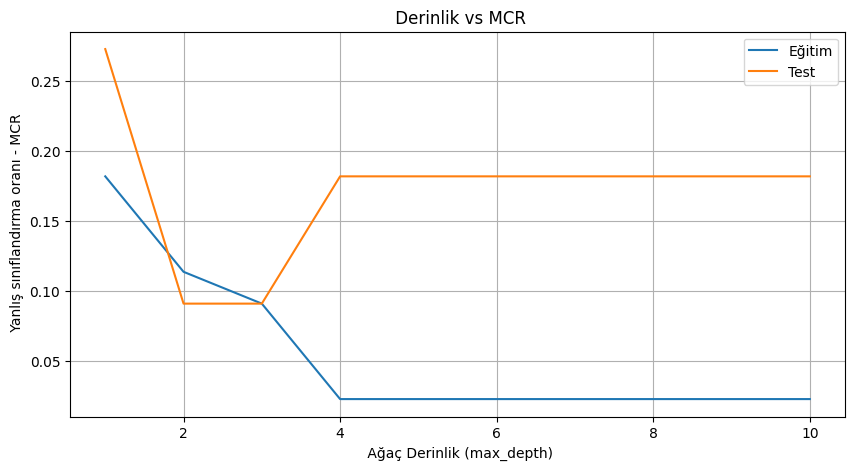

In [ ]:
# Sonuçları grafikle gösterelim

plt.figure(figsize=(10,5))
plt.plot(derinlikler, sonuclar_egitim, label="Eğitim")
plt.plot(derinlikler, sonuclar_test, label="Test")
plt.xlabel(" Ağaç Derinlik (max_depth)")
plt.ylabel(" Yanlış sınıflandırma oranı - MCR")
plt.title(" Derinlik vs MCR")
plt.legend()
plt.grid(True)
plt.show()

